# Лабораторная 2. Классическая обработка изображений

Вариант 9. В первой части сравниваются коррекция освещённости и подавление гауссова шума. Во второй строится маска животного без нейросетей и проверяется по trimap.

## 0. Установка и загрузка данных

Для запуска в Colab выберите Runtime → Run all. Первая ячейка загружает вариант из репозитория курса.

In [1]:
VARIANT = 9
DATA_SOURCE = None

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():

    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:


    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:

    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: ../data
Вариант 09 уже на месте: ../data/variant_09
данные варианта: ../data/variant_09
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import importlib.util
import subprocess

if ENV in ("colab", "kaggle"):
    packages = [package for module, package in (("skimage", "scikit-image"), ("pywt", "PyWavelets"))
                if importlib.util.find_spec(module) is None]
    if packages:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])

import time

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity

cv2.setNumThreads(1)

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

797 фото, 4 породы: american_bulldog, Persian, Sphynx, staffordshire_bull_terrier
OpenCV 5.1.0 | numpy 2.3.5 | pandas 2.2.3


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [3]:
MAX_SIDE = 512


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

american_bulldog_2.jpg (341, 512, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [4]:
def image_stats(rgb):
    light = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return {"mean_L": float(light.mean()), "std_L": float(light.std()),
            "noise_sigma": float(estimate_sigma(rgb.astype(np.float32), channel_axis=-1, average_sigmas=True)),
            "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var())}

In [5]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)


         width   height  mean_L   std_L  noise_sigma  sharpness
count   797.00   797.00  797.00  797.00       797.00     797.00
mean    447.96   408.32  121.46   58.66         1.53     592.74
std      93.81    90.04   32.08   13.70         1.18     756.58
min     161.00   168.00   31.17   23.19         0.00       5.89
25%     375.00   334.00  101.97   49.16         0.73     169.65
50%     500.00   375.00  122.53   58.92         1.20     325.87
75%     500.00   500.00  141.96   67.27         1.88     670.95
max    1280.00  1024.00  223.50  100.30         7.67    7285.78


,width,height,mean_L,std_L,noise_sigma,sharpness
count,797.00,797.00,797.00,797.00,797.00,797.00
mean,447.96,408.32,121.46,58.66,1.53,592.74
std,93.81,90.04,32.08,13.70,1.18,756.58
min,161.00,168.00,31.17,23.19,0.00,5.89
25%,375.00,334.00,101.97,49.16,0.73,169.65
50%,500.00,375.00,122.53,58.92,1.20,325.87
75%,500.00,500.00,141.96,67.27,1.88,670.95
max,1280.00,1024.00,223.50,100.30,7.67,7285.78


In [6]:
stats.groupby("breed")[["mean_L", "std_L", "noise_sigma", "sharpness"]].mean().round(2)


                            mean_L  std_L  noise_sigma  sharpness
breed                                                            
Persian                     126.26  55.21         1.28     371.78
Sphynx                      114.96  58.83         0.92     299.53
american_bulldog            115.56  60.49         1.72     696.23
staffordshire_bull_terrier  129.49  60.15         2.21    1023.67


,mean_L,std_L,noise_sigma,sharpness
breed,,,,
Persian,126.26,55.21,1.28,371.78
Sphynx,114.96,58.83,0.92,299.53
american_bulldog,115.56,60.49,1.72,696.23
staffordshire_bull_terrier,129.49,60.15,2.21,1023.67


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

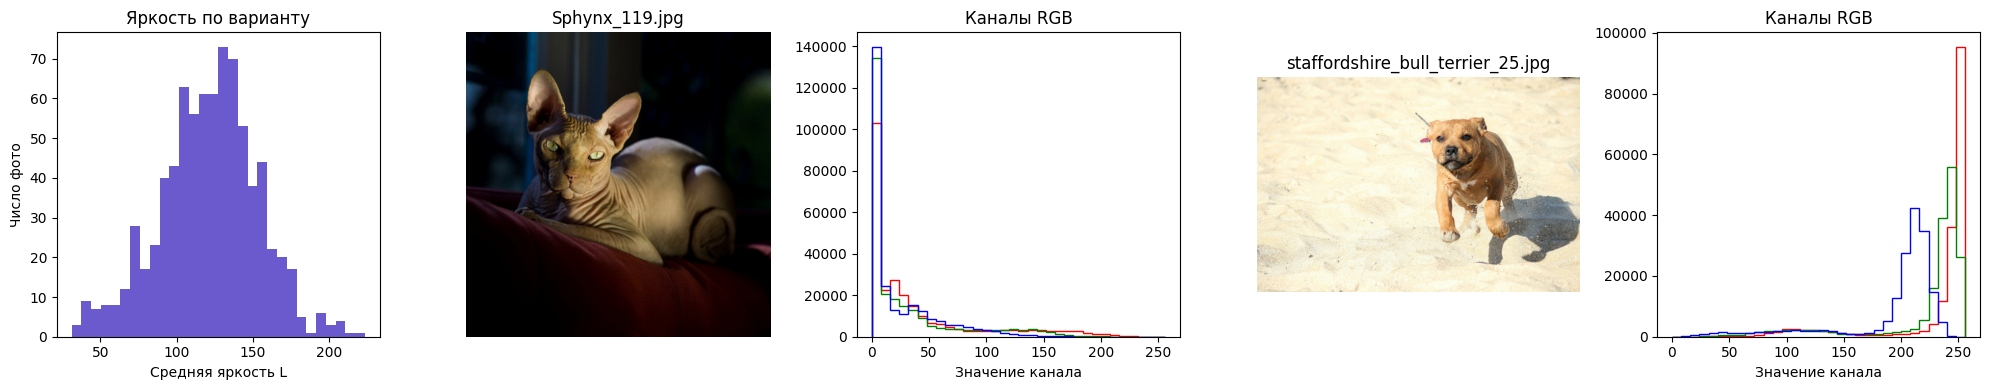

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].hist(stats["mean_L"], bins=30, color="slateblue")
axes[0].set(xlabel="Средняя яркость L", ylabel="Число фото", title="Яркость по варианту")
for j, idx in enumerate([stats["mean_L"].idxmin(), stats["mean_L"].idxmax()]):
    name = stats.loc[idx, "filename"]
    frame = load_rgb(name)
    image_ax, hist_ax = axes[1 + 2*j:3 + 2*j]
    image_ax.imshow(frame)
    image_ax.set_title(name)
    image_ax.axis("off")
    for c, color in enumerate("rgb"):
        hist_ax.hist(frame[..., c].ravel(), bins=32, range=(0, 256), color=color, histtype="step")
    hist_ax.set(xlabel="Значение канала", title="Каналы RGB")
fig.tight_layout()
fig.savefig(RESULTS / "histograms.png", dpi=110)
plt.show()

## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [8]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [9]:
GAMMA = 0.5

def correct(rgb, method):
    if method == "eq_rgb":
        return cv2.merge([cv2.equalizeHist(c) for c in cv2.split(rgb)])
    if method == "gamma":
        lut = np.rint(255 * (np.arange(256) / 255) ** GAMMA).astype(np.uint8)
        return cv2.LUT(rgb, lut)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    light = lab[..., 0]
    if method == "eq_L":
        lab[..., 0] = cv2.equalizeHist(light)
    elif method == "clahe_L":
        lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(light)
    else:
        raise ValueError(method)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


                    filename   method  mean_L  std_L  color_shift
0             Sphynx_119.jpg   eq_rgb  101.28  80.38        26.35
1             Sphynx_119.jpg     eq_L  101.90  81.74         0.85
2             Sphynx_119.jpg  clahe_L   47.63  58.79         0.37
3             Sphynx_119.jpg    gamma   67.26  62.16        13.43
4   american_bulldog_150.jpg   eq_rgb  136.80  71.61        10.78
5   american_bulldog_150.jpg     eq_L  134.36  68.28         0.20
6   american_bulldog_150.jpg  clahe_L   43.94  59.64         0.32
7   american_bulldog_150.jpg    gamma   77.97  58.15         4.15
8              Sphynx_46.jpg   eq_rgb  102.29  84.99         3.42
9              Sphynx_46.jpg     eq_L   99.90  82.00         0.07
10             Sphynx_46.jpg  clahe_L   52.81  62.93         0.33
11             Sphynx_46.jpg    gamma   71.95  67.47         1.35
12            Sphynx_158.jpg   eq_rgb  137.99  71.17        15.14
13            Sphynx_158.jpg     eq_L  136.41  68.36         0.16
14       

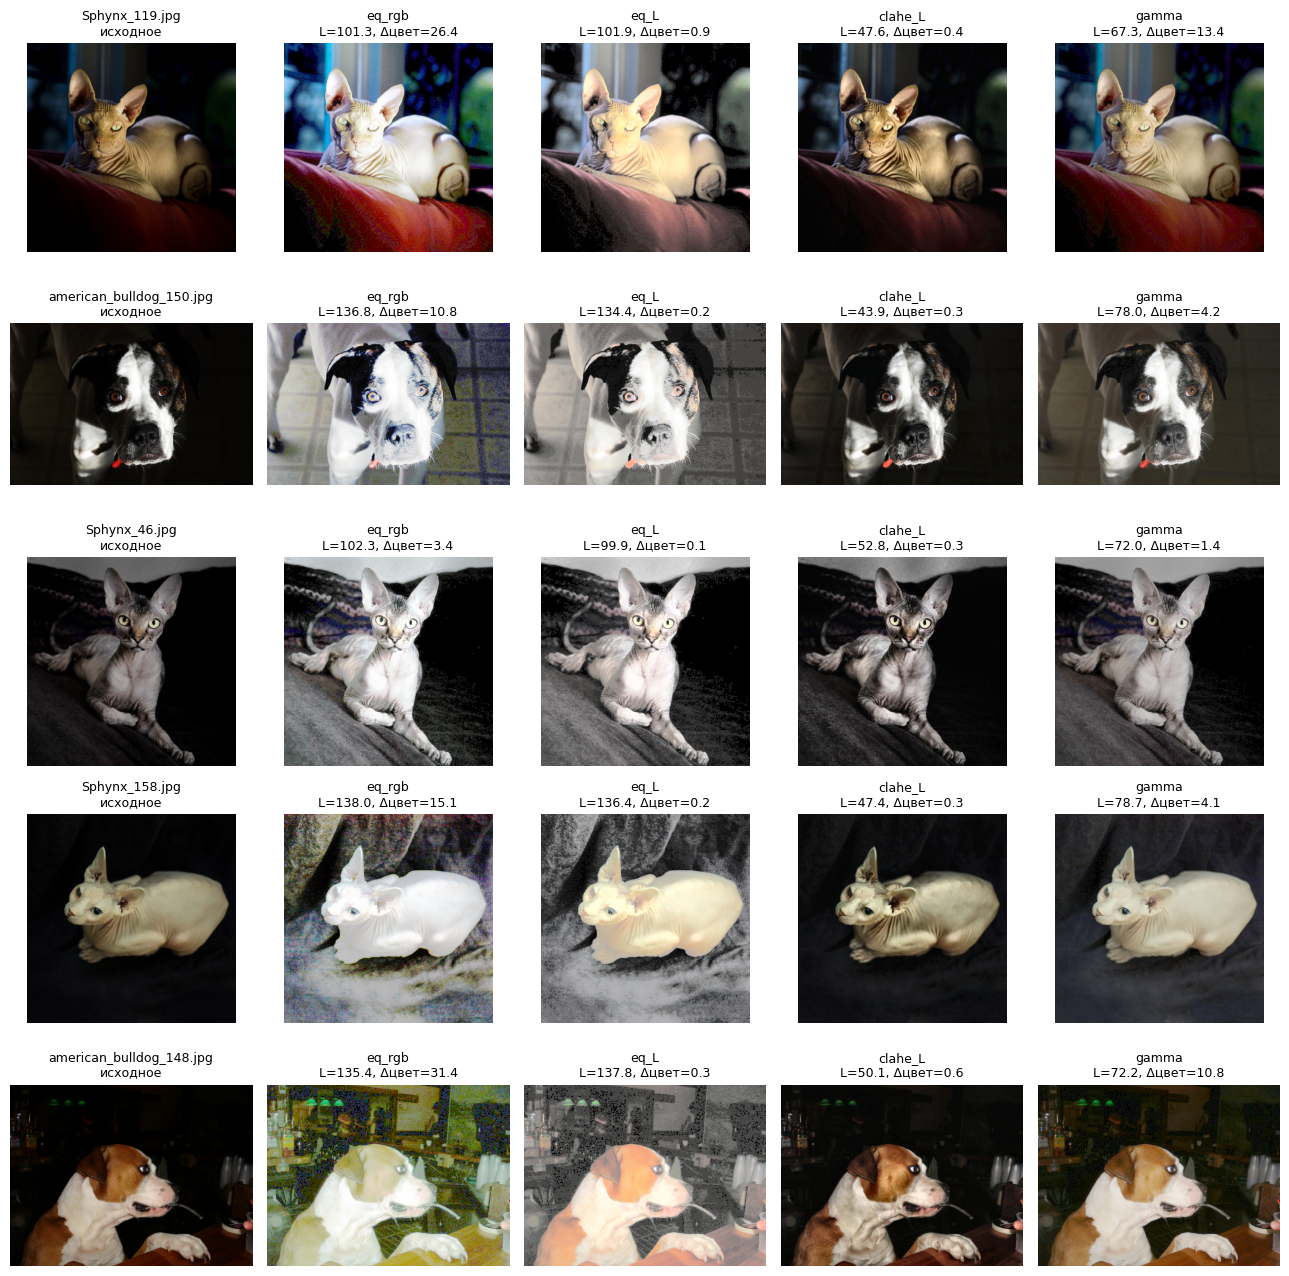

,filename,method,mean_L,std_L,color_shift
0,Sphynx_119.jpg,eq_rgb,101.28,80.38,26.35
1,Sphynx_119.jpg,eq_L,101.90,81.74,0.85
2,Sphynx_119.jpg,clahe_L,47.63,58.79,0.37
3,Sphynx_119.jpg,gamma,67.26,62.16,13.43
4,american_bulldog_150.jpg,eq_rgb,136.80,71.61,10.78
5,american_bulldog_150.jpg,eq_L,134.36,68.28,0.20
6,american_bulldog_150.jpg,clahe_L,43.94,59.64,0.32
7,american_bulldog_150.jpg,gamma,77.97,58.15,4.15
8,Sphynx_46.jpg,eq_rgb,102.29,84.99,3.42
9,Sphynx_46.jpg,eq_L,99.90,82.00,0.07


In [10]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]
rows, frames, captions = [], [], []
for name in stats.nsmallest(5, "mean_L")["filename"]:
    before = load_rgb(name)
    frames.append(before)
    captions.append(f"{name}\nисходное")
    for method in METHODS:
        after = correct(before, method)
        light = cv2.cvtColor(after, cv2.COLOR_RGB2LAB)[..., 0]
        delta = color_shift(before, after)
        rows.append(dict(filename=name, method=method, mean_L=light.mean(), std_L=light.std(), color_shift=delta))
        frames.append(after)
        captions.append(f"{method}\nL={light.mean():.1f}, Δцвет={delta:.1f}")
illum = pd.DataFrame(rows)
show_grid(frames, captions, ncols=5, path=RESULTS / "illumination.png", size=2.6)
illum.round(2)

## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

In [11]:
kernel = np.ones((3, 3), dtype=np.float32) / 9
manual = cv2.filter2D(example, -1, kernel)
blurred = cv2.blur(example, (3, 3))
error = int(np.abs(manual.astype(np.int16) - blurred.astype(np.int16)).max())
print("Максимальная разница:", error)
assert error == 0

Максимальная разница: 0


## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [12]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=gauss sigma=25


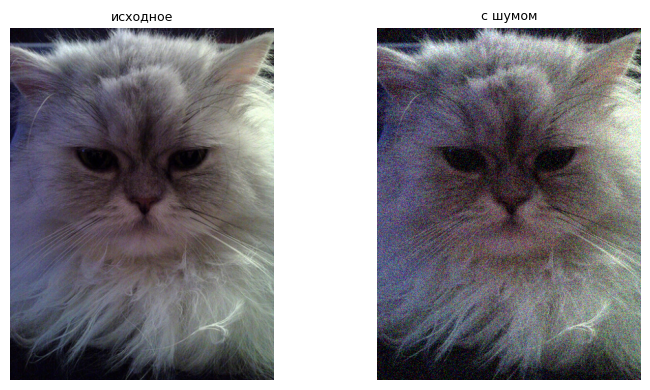

In [13]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [14]:
FILTERS = {}
for k in (3, 5, 7):
    FILTERS[f"blur{k}"] = lambda img, k=k: cv2.blur(img, (k, k))
    FILTERS[f"gauss{k}"] = lambda img, k=k: cv2.GaussianBlur(img, (k, k), 0)
    FILTERS[f"median{k}"] = lambda img, k=k: cv2.medianBlur(img, k)
FILTERS["bilateral"] = lambda img: cv2.bilateralFilter(img, 9, 55, 55)

In [15]:
def quality(clean_img, out_img):
    return {"psnr": float(cv2.PSNR(clean_img, out_img)),
            "ssim": float(structural_similarity(clean_img, out_img, channel_axis=-1, data_range=255))}

In [16]:
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary


                         noise       ms     psnr    ssim
filter                                                  
bilateral  kind=gauss sigma=25   4.0809  27.4782  0.6167
blur3      kind=gauss sigma=25   0.2034  27.9661  0.6635
blur5      kind=gauss sigma=25   0.1892  27.8390  0.7244
blur7      kind=gauss sigma=25   0.3739  26.8357  0.7120
gauss3     kind=gauss sigma=25   0.2248  27.8010  0.6431
gauss5     kind=gauss sigma=25   0.3756  28.6563  0.7193
gauss7     kind=gauss sigma=25   0.4204  28.5175  0.7550
median3    kind=gauss sigma=25   0.1563  26.8727  0.5909
median5    kind=gauss sigma=25   0.6658  27.9919  0.6925
median7    kind=gauss sigma=25  13.1907  27.5996  0.7116
none       kind=gauss sigma=25   0.0016  20.6324  0.3078


,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=gauss sigma=25,4.0809,27.4782,0.6167
blur3,kind=gauss sigma=25,0.2034,27.9661,0.6635
blur5,kind=gauss sigma=25,0.1892,27.8390,0.7244
blur7,kind=gauss sigma=25,0.3739,26.8357,0.7120
gauss3,kind=gauss sigma=25,0.2248,27.8010,0.6431
gauss5,kind=gauss sigma=25,0.3756,28.6563,0.7193
gauss7,kind=gauss sigma=25,0.4204,28.5175,0.7550
median3,kind=gauss sigma=25,0.1563,26.8727,0.5909
median5,kind=gauss sigma=25,0.6658,27.9919,0.6925


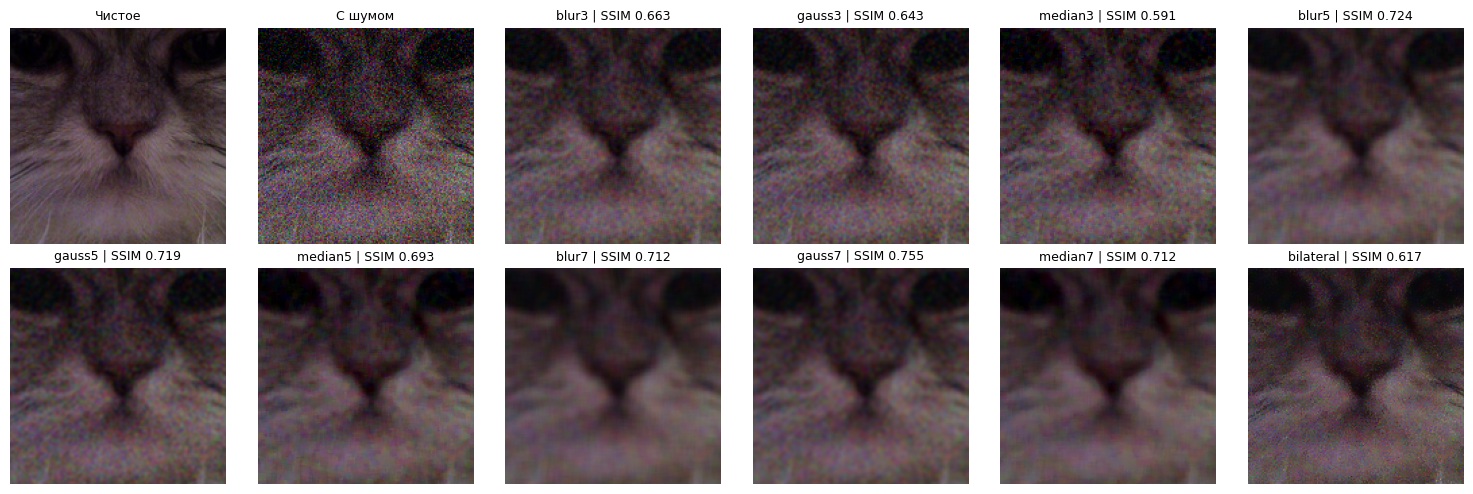

In [17]:
def center_crop(img, n=160):
    h, w = img.shape[:2]
    sy, sx = min(h, n), min(w, n)
    y, x = (h - sy) // 2, (w - sx) // 2
    return img[y:y+sy, x:x+sx]

names = ["Чистое", "С шумом"] + list(FILTERS)
images = [clean[0], noisy[0]] + [f(noisy[0]) for f in FILTERS.values()]
titles = names[:2] + [f"{name} | SSIM {filt_summary.loc[name, 'ssim']:.3f}" for name in names[2:]]
show_grid([center_crop(img) for img in images], titles, ncols=6, path=RESULTS / "filters.png", size=2.5)

In [18]:
ranked_filters = filt_summary.drop(index="none").sort_values("ssim", ascending=False)
BEST_FILTER = str(ranked_filters.index[0])
psnr_winner = str(ranked_filters["psnr"].idxmax())
print("Лучший по SSIM:", BEST_FILTER, "| лучший по PSNR:", psnr_winner)
ranked_filters

Лучший по SSIM: gauss7 | лучший по PSNR: gauss5

                         noise       ms     psnr    ssim
filter                                                  
gauss7     kind=gauss sigma=25   0.4204  28.5175  0.7550
blur5      kind=gauss sigma=25   0.1892  27.8390  0.7244
gauss5     kind=gauss sigma=25   0.3756  28.6563  0.7193
blur7      kind=gauss sigma=25   0.3739  26.8357  0.7120
median7    kind=gauss sigma=25  13.1907  27.5996  0.7116
median5    kind=gauss sigma=25   0.6658  27.9919  0.6925
blur3      kind=gauss sigma=25   0.2034  27.9661  0.6635
gauss3     kind=gauss sigma=25   0.2248  27.8010  0.6431
bilateral  kind=gauss sigma=25   4.0809  27.4782  0.6167
median3    kind=gauss sigma=25   0.1563  26.8727  0.5909


,noise,ms,psnr,ssim
filter,,,,
gauss7,kind=gauss sigma=25,0.4204,28.5175,0.7550
blur5,kind=gauss sigma=25,0.1892,27.8390,0.7244
gauss5,kind=gauss sigma=25,0.3756,28.6563,0.7193
blur7,kind=gauss sigma=25,0.3739,26.8357,0.7120
median7,kind=gauss sigma=25,13.1907,27.5996,0.7116
median5,kind=gauss sigma=25,0.6658,27.9919,0.6925
blur3,kind=gauss sigma=25,0.2034,27.9661,0.6635
gauss3,kind=gauss sigma=25,0.2248,27.8010,0.6431
bilateral,kind=gauss sigma=25,4.0809,27.4782,0.6167


**Почему выбран этот фильтр.** По среднему SSIM лидирует `gauss7` (0.7550 против 0.7244 у `blur5`). По PSNR лидирует `gauss5` (28.66 дБ), а `gauss7` занимает 0.420 мс на кадр. В сегментацию передаю лидера по SSIM, поскольку для порога важно сохранить структуру изображения.

# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [19]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out



CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

In [20]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

Persian_10.jpg (512, 384, 3) значения trimap: [1 2 3]


Порог Оцу: 106.0


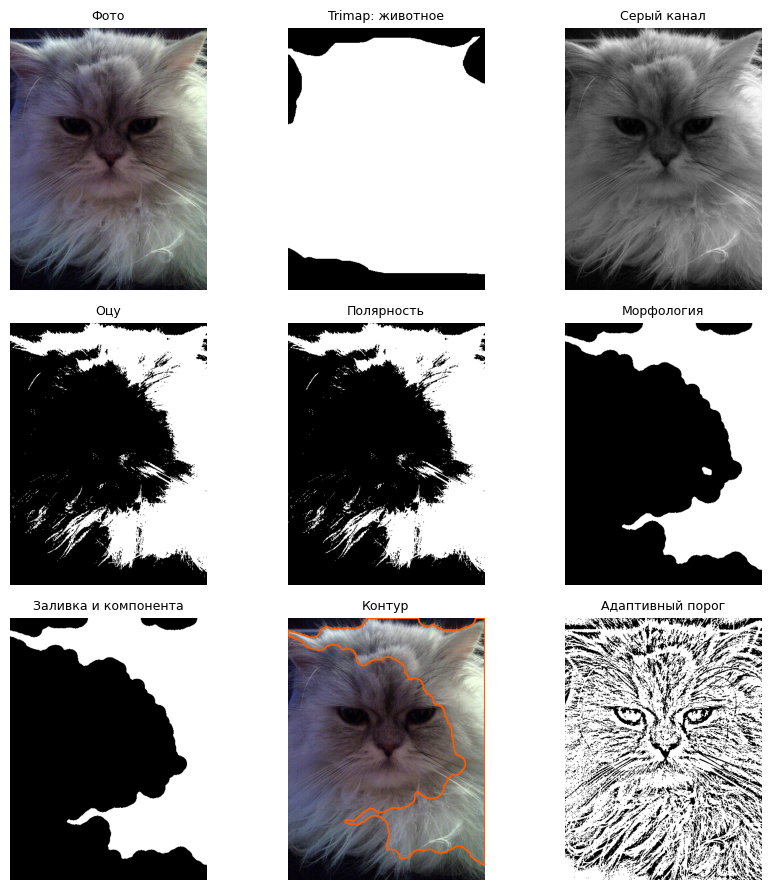

In [21]:
def fix_polarity(mask, border=10):
    edge = np.ones(mask.shape, dtype=bool)
    edge[border:-border, border:-border] = False
    return cv2.bitwise_not(mask) if np.count_nonzero(mask[edge]) > edge.sum() / 2 else mask

def morphology(mask, k_open, k_close):
    op = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open))
    cl = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close))
    return cv2.morphologyEx(cv2.morphologyEx(mask, cv2.MORPH_OPEN, op), cv2.MORPH_CLOSE, cl)

def fill_largest(mask):
    padded = np.pad(mask, 1, constant_values=0).astype(np.uint8, copy=False)
    cv2.floodFill(padded, None, (0, 0), 255)
    filled = mask | cv2.bitwise_not(padded[1:-1, 1:-1])
    n, components, details, _ = cv2.connectedComponentsWithStats(filled, connectivity=8)
    if n == 1:
        return np.zeros_like(mask)
    return ((components == (1 + np.argmax(details[1:, cv2.CC_STAT_AREA]))) * 255).astype(np.uint8)

gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
threshold, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
polar = fix_polarity(otsu)
morph = morphology(polar, 7, 31)
largest = fill_largest(morph)
adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 5)
contours, _ = cv2.findContours(largest, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
outlined = cv2.drawContours(rgb.copy(), contours, -1, (255, 90, 0), 2)
print("Порог Оцу:", threshold)
show_grid([rgb, (tri == 1), gray, otsu, polar, morph, largest, outlined, adaptive],
          ["Фото", "Trimap: животное", "Серый канал", "Оцу", "Полярность", "Морфология", "Заливка и компонента", "Контур", "Адаптивный порог"],
          ncols=3, path=RESULTS / "pipeline.png")

## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [22]:
def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True, fill=True, k_open=7, k_close=31):
    frame = FILTERS[BEST_FILTER](rgb) if smooth else rgb
    gray = CHANNELS[channel](frame)
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if polarity:
        mask = fix_polarity(mask)
    if morph:
        mask = morphology(mask, k_open, k_close)
    if fill:
        mask = fill_largest(mask)
    return mask > 0

In [23]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(rgb, **kw), tri) for name, kw in configs.items()}})
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(3)

In [24]:
channel_scores = evaluate({name: dict(channel=name) for name in ("gray", "S")})
channel_summary = summarize(channel_scores)
CHANNEL = str(channel_scores.mean().idxmax())
print("Выбранный канал:", CHANNEL)
channel_summary

Выбранный канал: gray

      mean_iou  median_iou
gray     0.479       0.481
S        0.392       0.331


,mean_iou,median_iou
gray,0.479,0.481
S,0.392,0.331


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [25]:
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: gray | фильтр: gauss7

                          mean_iou  median_iou
1 только Оцу                 0.342       0.290
2 + фильтр из части 1        0.346       0.291
3 + полярность               0.430       0.422
4 + морфология               0.458       0.449
5 + заливка и компонента     0.479       0.481


,mean_iou,median_iou
1 только Оцу,0.342,0.290
2 + фильтр из части 1,0.346,0.291
3 + полярность,0.430,0.422
4 + морфология,0.458,0.449
5 + заливка и компонента,0.479,0.481


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [26]:
def shape_features(mask):
    keys = ("area_frac", "perimeter", "x", "y", "w", "h", "elongation", "circularity", "solidity")
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return dict.fromkeys(keys, float("nan"))
    c = max(contours, key=cv2.contourArea)
    area, perimeter = cv2.contourArea(c), cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c)
    short, long = sorted(cv2.minAreaRect(c)[1])
    hull = cv2.contourArea(cv2.convexHull(c))
    return dict(area_frac=area / mask.size, perimeter=perimeter, x=x, y=y, w=w, h=h,
                elongation=long / short if short else float("nan"),
                circularity=4 * np.pi * area / perimeter**2 if perimeter else float("nan"),
                solidity=area / hull if hull else float("nan"))

In [27]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()


                 filename             breed  ... circularity  solidity
0  american_bulldog_2.jpg  american_bulldog  ...    0.445786  0.847794
1  american_bulldog_3.jpg  american_bulldog  ...    0.101354  0.594052
2  american_bulldog_5.jpg  american_bulldog  ...    0.262982  0.679406
3  american_bulldog_6.jpg  american_bulldog  ...    0.403855  0.816980
4  american_bulldog_7.jpg  american_bulldog  ...    0.310610  0.758201

[5 rows x 13 columns]


,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,american_bulldog_2.jpg,american_bulldog,dog,0.541192,0.458878,1502.805253,0,0,388,341,1.495976,0.445786,0.847794
1,american_bulldog_3.jpg,american_bulldog,dog,0.034441,0.527188,3136.721996,0,0,512,268,1.923678,0.101354,0.594052
2,american_bulldog_5.jpg,american_bulldog,dog,0.148517,0.472265,2106.371708,0,0,384,470,1.224543,0.262982,0.679406
3,american_bulldog_6.jpg,american_bulldog,dog,0.339358,0.485352,1725.383898,0,63,506,322,1.573209,0.403855,0.816980
4,american_bulldog_7.jpg,american_bulldog,dog,0.112769,0.533384,1941.016371,0,0,341,402,1.179412,0.310610,0.758201


In [28]:
shape_cols = ["iou", "area_frac", "elongation", "circularity", "solidity"]
display(masks.groupby("species")[shape_cols].mean().round(3))
masks.groupby("breed")[shape_cols].mean().round(3)


                              iou  area_frac  elongation  circularity  solidity
breed                                                                          
Persian                     0.546      0.467       1.419        0.353     0.756
Sphynx                      0.442      0.399       1.497        0.299     0.703
american_bulldog            0.494      0.414       1.539        0.291     0.701
staffordshire_bull_terrier  0.433      0.441       1.453        0.287     0.718


,iou,area_frac,elongation,circularity,solidity
species,,,,,
cat,0.494,0.433,1.458,0.326,0.729
dog,0.464,0.427,1.497,0.289,0.709


,iou,area_frac,elongation,circularity,solidity
breed,,,,,
Persian,0.546,0.467,1.419,0.353,0.756
Sphynx,0.442,0.399,1.497,0.299,0.703
american_bulldog,0.494,0.414,1.539,0.291,0.701
staffordshire_bull_terrier,0.433,0.441,1.453,0.287,0.718


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

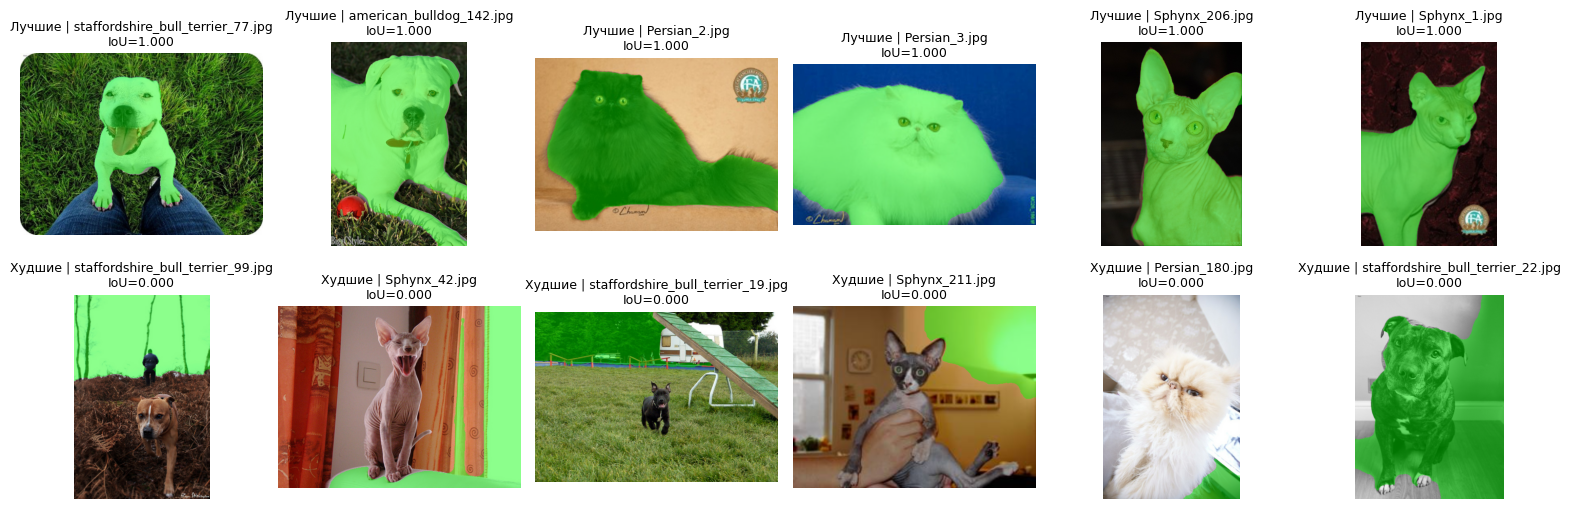

In [29]:
ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
rows = [(title, row) for title, table in [("Лучшие", ranked.head(6)), ("Худшие", ranked.tail(6).iloc[::-1])]
        for row in table.itertuples()]
figures, titles = [], []
for title, row in rows:
    frame = load_rgb(row.filename)
    figures.append(overlay(frame, segment(frame, **FINAL)))
    titles.append(f"{title} | {row.filename}\nIoU={row.iou:.3f}")
show_grid(figures, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.6)

## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [30]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")

expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")
assert not missing, missing
assert len(stats) == len(masks) == len(labels)
assert masks["filename"].is_unique

вариант 9 | шум kind=gauss sigma=25 | BEST_FILTER = gauss7 | CHANNEL = gray
не хватает: ничего, все 9 файлов на месте


In [31]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)